# [Lecture 09 - Modeling Events](https://www.youtube.com/watch?v=Zi6N3GLUJmw)

In [1]:
%run init_notebook.py

Module aliases imported by init_notebook.py:
--------------------------------------------
import numpy as np

import pandas as pd

import statsmodels.formula.api as smf

import pymc as pm

import xarray as xr

import arviz as az

import utils as utils

from scipy import stats as stats

from matplotlib import pyplot as plt

Watermark:
----------
Last updated: 2026-10-16T08:48:23.587245+02:00

Python implementation: CPython
Python version       : 3.14.8
IPython version      : 9.17.1

Compiler    : MSC v.1944 64 bit (AMD64)
OS          : Windows
Release     : 11
Machine     : AMD64
Processor   : Intel64 Family 6 Model 154 Stepping 3, GenuineIntel
CPU cores   : 20
Architecture: 64bit

IPython    : 9.17.1
arviz      : 1.3.0
matplotlib : 3.11.2
numpy      : 2.5.4
pandas     : 3.0.6
pymc       : 6.3.2
scipy      : 1.18.1
statsmodels: 0.15.0
watermark  : 2.6.0
xarray     : 2026.9.0



# UC Berkeley Admissions

## Dataset
- 4562 Graduate student applications
- Stratified by
  - Department
  - Gender

Goal is to identify gender discrimination by admissions officers

In [2]:
ADMISSIONS = utils.load_data("UCBadmit")
ADMISSIONS

,dept,applicant.gender,admit,reject,applications
1,A,male,512,313,825
2,A,female,89,19,108
3,B,male,353,207,560
4,B,female,17,8,25
5,C,male,120,205,325
6,C,female,202,391,593
7,D,male,138,279,417
8,D,female,131,244,375
9,E,male,53,138,191
10,E,female,94,299,393


## Modeling Events
- **Events**: discrete, unordered outcomes
- Observations are counts/aggregates
- Unknowns are probabilities $p$ of event ocurring, or odds of those probabilities $\frac{p}{1-p}$
- All things we stratify by interact -- generally never independent in real life
- Often deal with the Log Odds of $p = \log \left (\frac{p}{1-p} \right)$

## Admissions: Drawing the owl 🦉
    
1. Estimands(s)
2. Scientific Models(s)
3. Statistical Models(s)
4. Analysis

# 1. Estimand(s)

## Which path defines "discrimination"

### Direct Discrimination (Causal Effect)

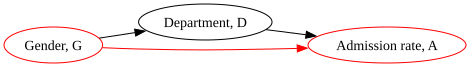

In [3]:
utils.draw_causal_graph(
    edge_list=[
        ("G", "D"),
        ("G", "A"),
        ("D", "A")
    ],
    node_props={
        "G": {"label": "Gender, G", "color": "red"},
        "D": {"label": "Department, D"},
        "A": {"label": "Admission rate, A", "color": "red"},
    },
    edge_props={
        ("G", "A"): {"color": "red"}
    },
    graph_direction="LR"
)

- aka "Institutional discrimination"
- Referees are biased for or against a particular group
- Usually the type we're interested in identifying if it exists
- Requires strong causal assumptions

Here, deparment, D is a mediator -- this is a common structure in social sciences, where categorical status (e.g. gender) effects some mediating context (e.g. occupation), both of which affect a target outcome (wage). Examples
- wage discrimination
- hiring
- scientific awards


### Indirect Discrimination

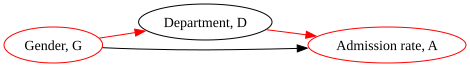

In [4]:
utils.draw_causal_graph(
    edge_list=[
        ("G", "D"),
        ("G", "A"),
        ("D", "A")
    ],
    node_props={
        "G": {"label": "Gender, G", "color": "red"},
        "D": {"label": "Department, D"},
        "A": {"label": "Admission rate, A", "color": "red"},
    },
    edge_props={
        ("G", "D"): {"color": "red"},
        ("D", "A"): {"color": "red"}
    },
    graph_direction="LR"
)

- aka "Structural discrimination"
- e.g. Gender affects a person's interests, and therefore the department they will apply to
- Affects overall admission rates
- Requires strong causal assumptions

### Total Discrimination

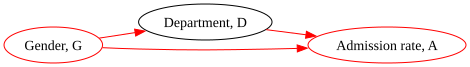

In [5]:
utils.draw_causal_graph(
    edge_list=[
        ("G", "D"),
        ("G", "A"),
        ("D", "A")
    ],
    node_props={
        "G": {"label": "Gender, G", "color": "red"},
        "D": {"label": "Department, D"},
        "A": {"label": "Admission rate, A", "color": "red"},
    },
    edge_props={
        ("G", "D"): {"color": "red"},
        ("G", "A"): {"color": "red"},
        ("D", "A"): {"color": "red"}
    },
    graph_direction="LR"
)

- aka "Experienced discrimination"
- through both direct and indirect routes
- Requires mild assumptions

### Estimands & Estimators
- Each of the **different estimands require a different estimators**
- Often the thing we **can estimate** often isn't what we **want to estimate**
- e.g. Total discrimination may be easier to estimate, but is less actionable

## Unobserved Confounds

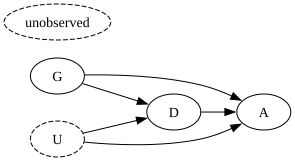

In [6]:
utils.draw_causal_graph(
    edge_list=[
        ("G", "D"),
        ("G", "A"),
        ("D", "A"),
        ("U", "D"),
        ("U", "A")
    ],
    node_props={
        "U": {"style": "dashed"},
        "unobserved": {"style": "dashed"}
    },

    graph_direction="LR"
)

It's always possible there are also confounds between the mediator and some unobserved confounds. We will ignore these for now.

# 2. Scientific Model(s):

## Simulate the process
Below is a generative model of the review/admission process

In [7]:
np.random.seed(123)
n_samples = 1000

GENDER = stats.bernoulli.rvs(p=.5, size=n_samples)

# Groundtruth parameters
# Gender 1 tends to apply to department 1
P_DEPARTMENT = np.where(GENDER==0, .3, .8)

# Acceptance rates matrices -- Department x Gender
UNBIASED_ACCEPTANCE_RATES = np.array([[.1, .1], [.3, .3]])  # No *direct* gender bias

# Biased acceptance: 
# - dept 0 accepts gender 0 at 50% of unbiased rate 
# - dept 1 accepts gender 0 at 67% of unbiased rate
BIASED_ACCEPTANCE_RATES = np.array([[.05, .1], [.2, .3]])   # *direct* gender bias present

DEPARTMENT = stats.bernoulli.rvs(p=P_DEPARTMENT, size=n_samples).astype(int)


def simulate_admissions_data(bias_type):
    """Simulate admissions data using the global params above"""
    acceptance_rate = BIASED_ACCEPTANCE_RATES if bias_type == 'biased' else UNBIASED_ACCEPTANCE_RATES
    acceptance = stats.bernoulli.rvs(p=acceptance_rate[DEPARTMENT, GENDER])
    
    return pd.DataFrame(
        np.vstack([GENDER, DEPARTMENT, acceptance]).T,
        columns=['gender', 'department', 'accepted']
    ), acceptance_rate

for bias_type in ['unbiased', 'biased']:

    fake_admissions, acceptance_rate = simulate_admissions_data(bias_type)
    
    gender_acceptance_counts = fake_admissions.groupby(["gender", "accepted"]).count()['department']
    gender_acceptance_counts.name = None
    
    gender_department_counts = fake_admissions.groupby(["gender", "department"]).count()['accepted']
    gender_department_counts.name = None
    
    observed_acceptance_rates = fake_admissions.groupby("gender").mean()['accepted']
    observed_acceptance_rates.name = None
    
    print()
    print('-' * 30)
    print(bias_type.upper())
    print('-' * 30)
    print(f'Department Acceptance rate:\n{acceptance_rate}')
    print(f'\nGender-Department Frequency:\n{gender_department_counts}')
    print(f'\nGender-Acceptance Frequency:\n{gender_acceptance_counts}')
    print(f'\nOverall Acceptance Rates:\n{observed_acceptance_rates}')


------------------------------
UNBIASED
------------------------------
Department Acceptance rate:
[[0.1 0.1]
 [0.3 0.3]]

Gender-Department Frequency:
gender  department
0       0             335
        1             173
1       0             106
        1             386
dtype: int64

Gender-Acceptance Frequency:
gender  accepted
0       0           437
        1            71
1       0           359
        1           133
dtype: int64

Overall Acceptance Rates:
gender
0    0.139764
1    0.270325
dtype: float64

------------------------------
BIASED
------------------------------
Department Acceptance rate:
[[0.05 0.1 ]
 [0.2  0.3 ]]

Gender-Department Frequency:
gender  department
0       0             335
        1             173
1       0             106
        1             386
dtype: int64

Gender-Acceptance Frequency:
gender  accepted
0       0           465
        1            43
1       0           370
        1           122
dtype: int64

Overall Acceptance Rates:
gend

### Simulated data properties

#### Both scenarios

- Gender 0 tends to apply to department 0
- Gender 1 tends to apply to department 1

#### Unbiased scenario:
- due to lower acceptance rates in dept 0 and tendency of gender 0 to apply to dept 0, gender 0 has a lower overall rejection rate compared to gender 1
- due to higher acceptance rates in dept 1 and tendency of gender 1 to apply to dept 1, gender 1 has a higher overall acceptance rate compared to gender 0
- even in the case of no (direct) gender discrimination, **there is still indirect discrimination based on tendency of genders to apply to different departments, and the unqual likelihood that each department accepts students.**

#### Biased scenario
- overall acceptance rates are lower (due to baseline reduction in gender 0 acceptance rates across both departments)
- in the scenario where there is actual department bias, **we see a similar overall _pattern_ of discrimination as the unbiased case due to the indirect effect.**

# 3. Statistical Models

## Modeling Events
- **We observe** counts of events
- **We estimate** probabilities -- or, rather, the log-odds of events ocurring


### Linear Models
Expected value is linear (additive) combination of parameters

$$
\begin{align*}
Y_i &\sim \mathcal{N}(\mu_i, \sigma) \\
\mu_i &= \alpha + \beta_X X_i + ...
\end{align*}
$$

b.c. Normal distribution is **unbounded**, so too is the expected value of the linear model.

### Event Models
Discrete events either occur, taking the value 1, or they do not, taking the value 0. This **puts bounds** on the expected value of an event. Namely the bounds are on the interval $(0, 1)$

## Generalized Linear Models & Link Functions

- Expected value is **some function $f(\mathbb{E}[\theta])$ of an additive combination of the parameters**.

$$
f(\mathbb{E}[\theta]) = \alpha + \beta_X X_i + ...
$$

- Generally, this function $f()$, called the **link function**, will have a specific form **that is associated with the likelihood distribution**. 
- the link function will have an **inverse link function** $ f^{-1}(X_i, \theta)$ such that
- to reiterate **link functions are matched to distributions**

$$
\mathbb{E}[\theta] = f^{-1}(\alpha + \beta_X X_i + ...)
$$

- In the linear regression case the likelihood model is Gaussian, and the associated link function (and inverse link function) is just the identity, $I()$. (left plot below)



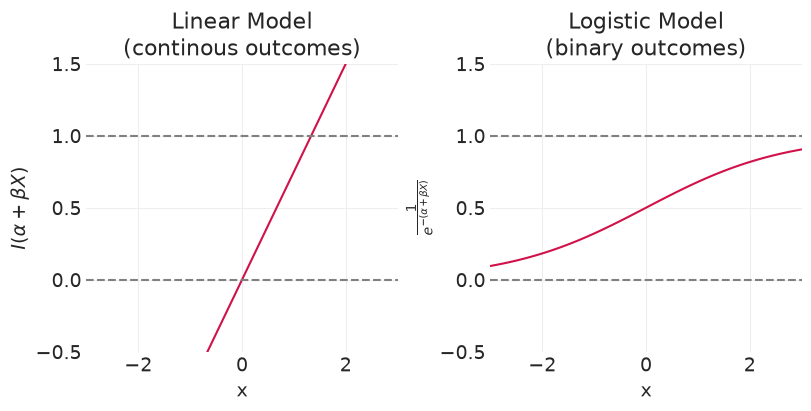

In [8]:
_, axs = plt.subplots(1, 2, figsize=(8, 4))
xs = np.linspace(-3, 3, 100)
plt.sca(axs[0])
alpha = 0
beta = .75

plt.plot(xs, alpha + beta * xs)
plt.axhline([0], linestyle='--', color='gray')
plt.axhline([1], linestyle='--', color='gray')
plt.xlim([-3, 3])
plt.ylim([-.5, 1.5])
plt.xlabel('x')
plt.ylabel('$I(\\alpha + \\beta X$)');
plt.title("Linear Model\n(continous outcomes)")

plt.sca(axs[1])
plt.plot(xs, utils.invlogit(alpha + beta * xs))
plt.axhline([0], linestyle='--', color='gray')
plt.axhline([1], linestyle='--', color='gray')
plt.xlim([-3, 3])
plt.ylim([-.5, 1.5])
plt.xlabel('x')
plt.ylabel('$\\frac{1}{e^{-(\\alpha + \\beta X)}}$');
plt.title("Logistic Model\n(binary outcomes)");

## Logit Link Function and Logisitic Inverse function
### Binary outcomes

- **Logistic regression** used to model the probability of an event ocurring
- Likelihood function is the Bernouilli
- Associated link function is the **log-odds, or logit**: $f(p) = \frac{p}{1-p}$

$$
\begin{align*}
Y_i &\sim \text{Bernoulli}(p_i) \\
f(p_i) &= \alpha + \beta_X X_i + ...
\end{align*}
$$

- the inverse link function is the **inverse logit** aka **logistic** function (right plot above): $f^{-1}(X_i, \theta) = \frac{1}{1 + e^{-(\alpha + \beta_X X_i + ...)}}$
  - defining $\alpha + \beta_X X + ... = q$ (ignoring the data index $i$ for now), the derivation of the inverse logit is as follows
$$
\begin{align}
\log \left(\frac{p}{1-p}\right) &= \alpha + \beta_X X + ... = q \\
\frac{p}{1-p} &= e^{q} \\
p &= (1-p) e^{q} \\
p + p e^{q} &= e^{q} \\
p(1 + e^{q}) &= e^{q} \\
p &= \frac{ e^{q}}{(1 + e^{q})} \\
p &= \frac{ e^{q}}{(1 + e^{q})} \frac{e^{-q}}{e^{-q}}\\
p &= \frac{1}{(1 + e^{-q})} \\
\end{align}
$$

### logit is a harsh transform
Interpreting the log odds can be difficult at first, but in time becomes easier
- log-odds scale
- $\text{logit}(p)=0, p=0.5$
- $\text{logit}(p)=-\infty, p=0$
  - rule of thumb: $\text{logit}(p)<-4$ means event is unlikely (hardly ever)
- $\text{logit}(p)=\infty, p=1$
  - rule of thumb: $\text{logit}(p)>4$ means event is very likely (nearly always)

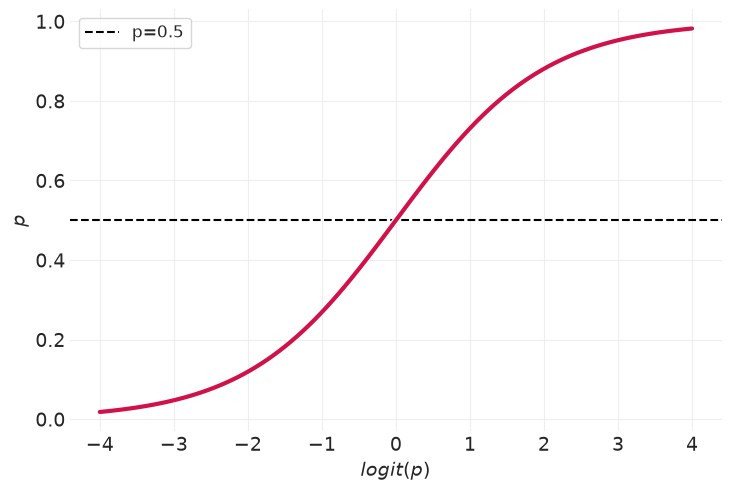

In [9]:
log_odds = np.linspace(-4, 4, 100)
utils.plot_line(log_odds, utils.invlogit(log_odds), label=None)
plt.axhline(0.5, linestyle="--", color='k', label="p=0.5")
plt.xlabel("$logit(p)$")
plt.ylabel("$p$")
plt.legend();

### Bayesian Updating for Logistic Regression
For the following simulation, we'll use a custom utility function `utils.simulate_2_parameter_bayesian_learning` for simulating general Bayeisan posterior update simulation. Here's the API for that function (for more details see `utils.py`)

In [10]:
help(utils.simulate_2_parameter_bayesian_learning)

Help on function simulate_2_parameter_bayesian_learning in module utils:

simulate_2_parameter_bayesian_learning(
    x_obs,
    y_obs,
    param_a_grid,
    param_b_grid,
    true_param_a,
    true_param_b,
    model_func,
    posterior_func,
    n_posterior_samples=3,
    param_labels=None,
    data_range_x=None,
    data_range_y=None
)
    General function for simulating Bayesian learning in a 2-parameter model
    using grid approximation.

    Parameters
    ----------
    x_obs : np.ndarray
        The observed x values
    y_obs : np.ndarray
        The observed y values
    param_a_grid: np.ndarray
        The range of values the first model parameter in the model can take.
        Note: should have same length as param_b_grid.
    param_b_grid: np.ndarray
        The range of values the second model parameter in the model can take.
        Note: should have same length as param_a_grid.
    true_param_a: float
        The true value of the first model parameter, used for visual

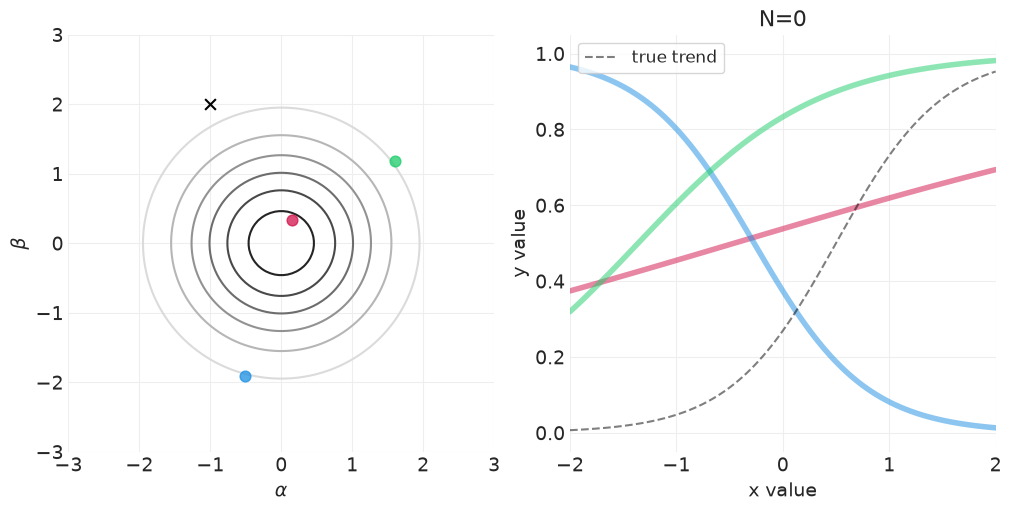

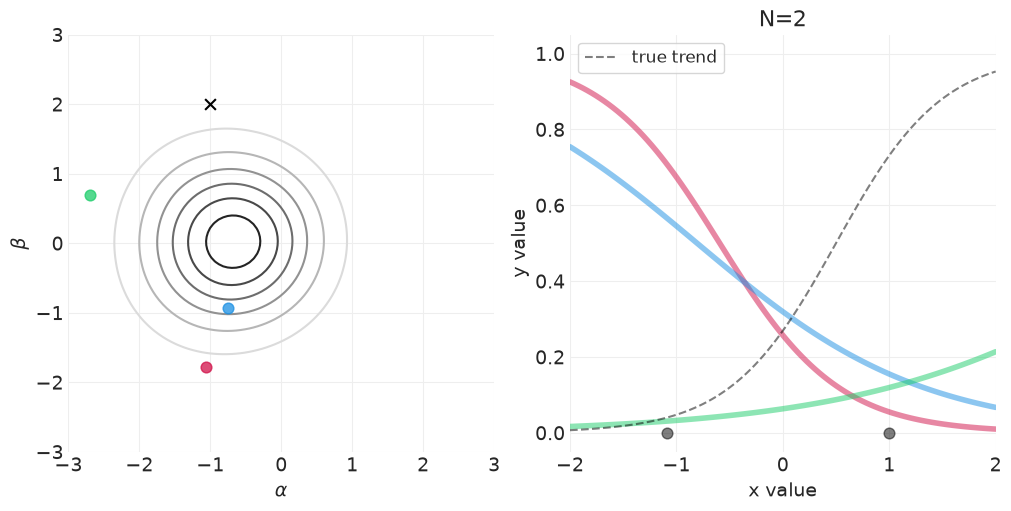

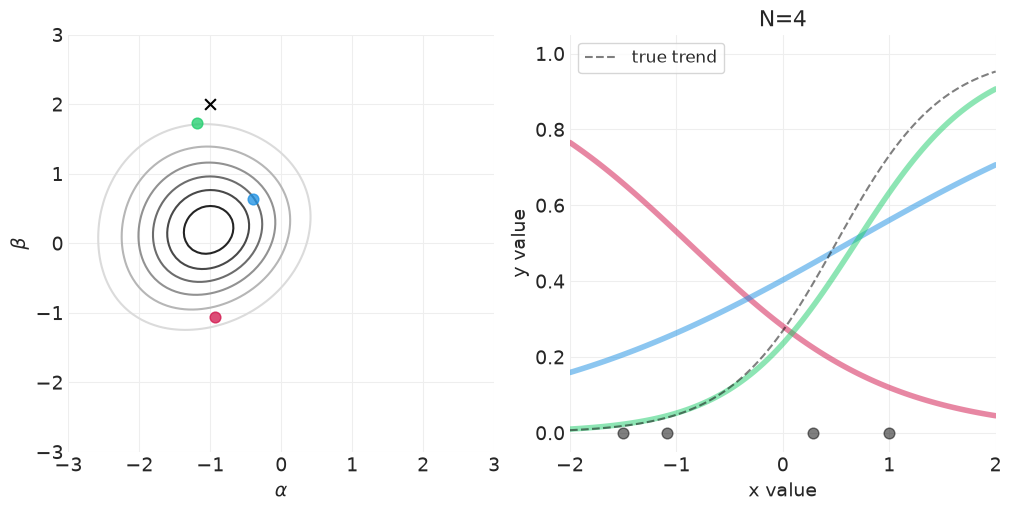

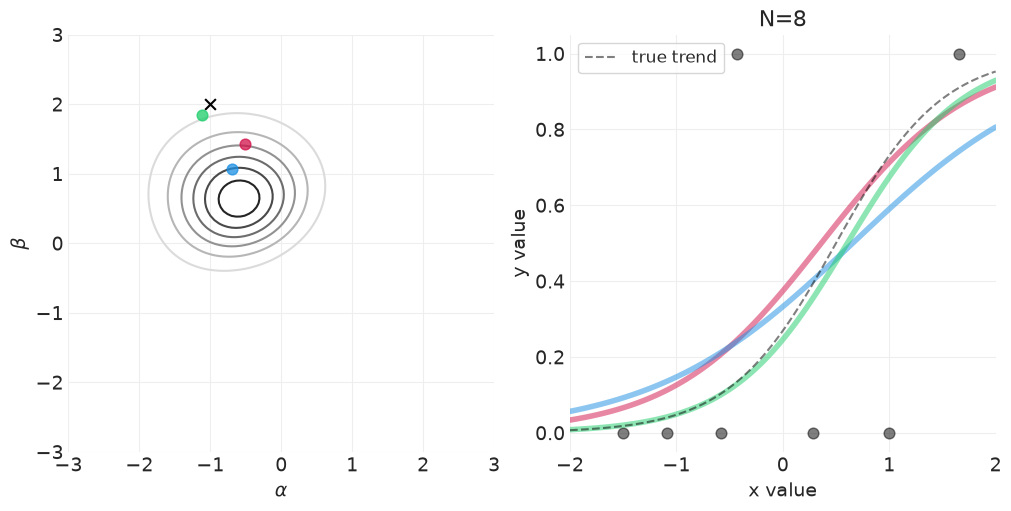

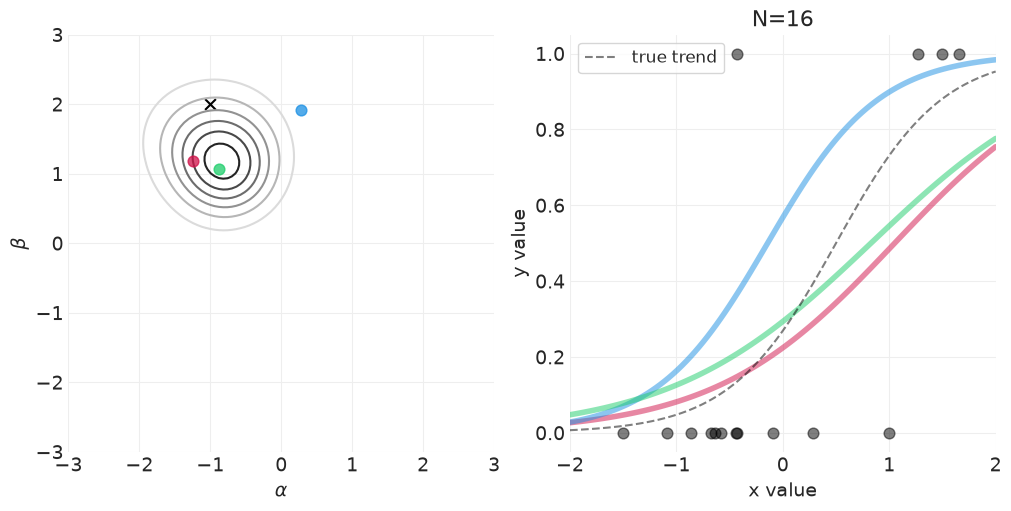

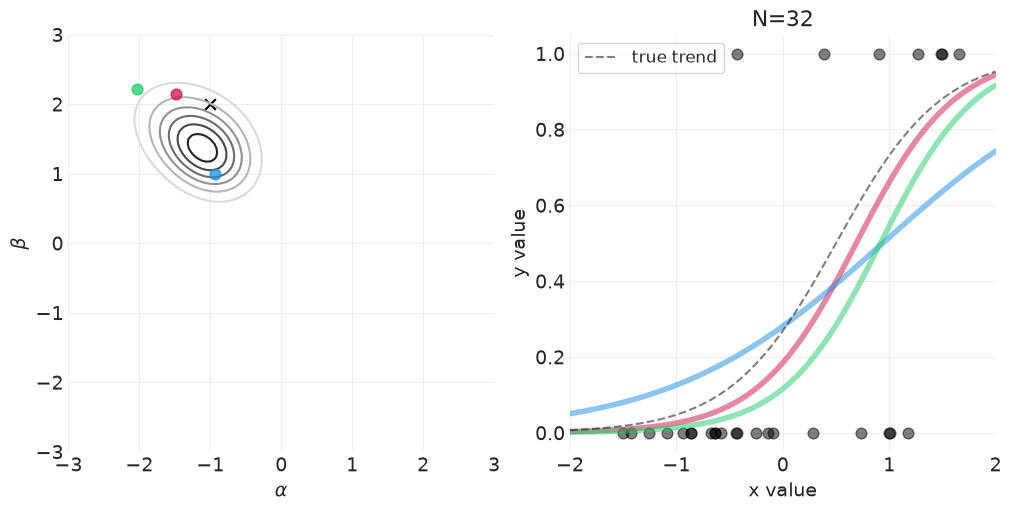

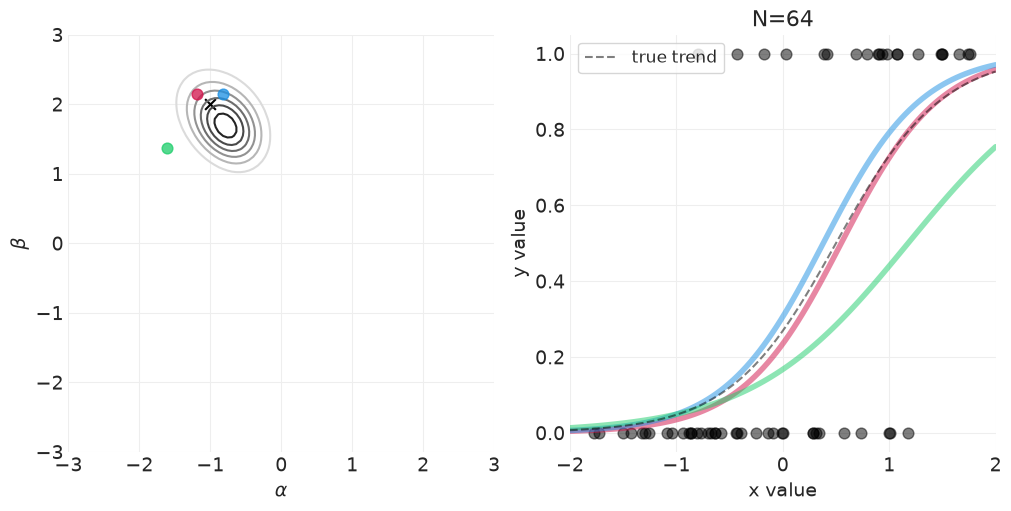

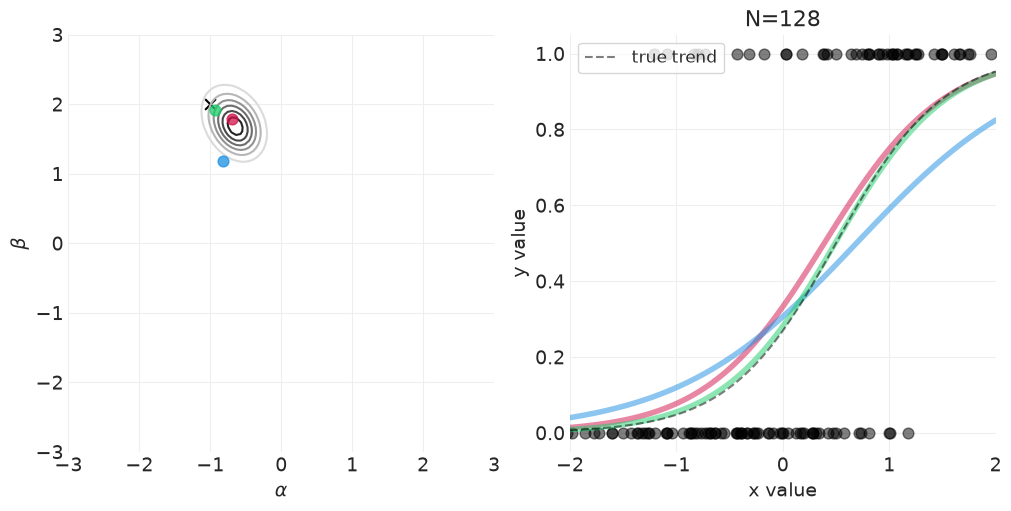

In [11]:
# Model function required for simulation
def logistic_model(x, alpha, beta):
    return utils.invlogit(alpha + beta * x)

# Posterior function required for simulation
def logistic_regression_posterior(x_obs, y_obs, alpha_grid, beta_grid, likelihood_prior_std = .01):
    
    # Convert params to 1-d arrays
    if np.ndim(alpha_grid) > 1:
        alpha_grid = alpha_grid.ravel()
    
    if np.ndim(beta_grid):
        beta_grid = beta_grid.ravel()
    
    log_prior_intercept = stats.norm(0, 1).logpdf(alpha_grid)
    log_prior_slope = stats.norm(0, 1).logpdf(beta_grid)
    
    log_likelihood = np.array(
        [
            stats.bernoulli(
                p=utils.invlogit(a + b * x_obs)
            ).logpmf(y_obs) for a, b in zip(alpha_grid, beta_grid)
        ]
    ).sum(axis=1)
    
    # Posterior is equal to the product of likelihood and priors (here a sum in log scale)
    log_posterior = log_likelihood + log_prior_intercept + log_prior_slope

    # Convert back to natural scale
    return np.exp(log_posterior - log_posterior.max())

# Generate data for demo
np.random.seed(123)
RESOLUTION = 100
N_DATA_POINTS = 128

# Ground truth parameters
ALPHA = -1
BETA = 2

x = stats.norm(0, 1).rvs(size=N_DATA_POINTS)
p_y = utils.invlogit(ALPHA + BETA * x)
y = stats.bernoulli.rvs(p=p_y)

alpha_grid = np.linspace(-3, 3, RESOLUTION)
beta_grid = np.linspace(-3, 3, RESOLUTION)

# Vary the sample size to show how the posterior adapts to more and more data
for n_samples in [0, 2, 4, 8, 16, 32, 64, 128]:
    # Run the simulation
    utils.simulate_2_parameter_bayesian_learning(
        x_obs=x[:n_samples],
        y_obs=y[:n_samples],
        param_a_grid=alpha_grid,
        param_b_grid=beta_grid,
        true_param_a=ALPHA,
        true_param_b=BETA,
        model_func=logistic_model,
        posterior_func=logistic_regression_posterior,
        param_labels=['$\\alpha$', '$\\beta$'],
        data_range_x=(-2, 2), data_range_y=(-.05, 1.05)
    )

## Priors for logistic regression

**logit link function is a harsh transform**
- Logit compresses parameter distributions
- $x > +4 \rightarrow $ event basically always occurs
- $x < -4 \rightarrow$ event basically never occurs

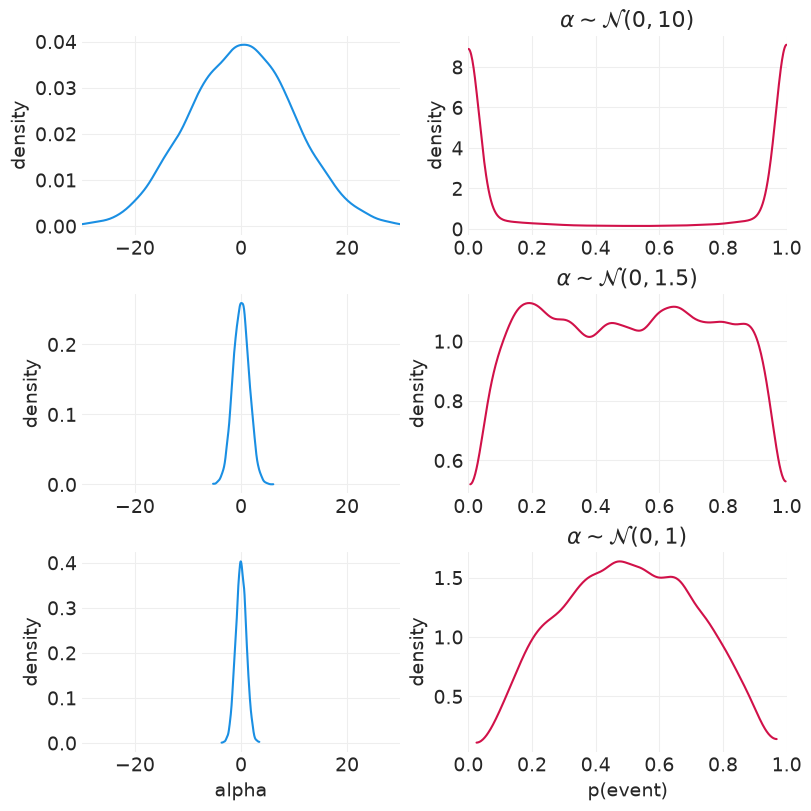

In [12]:
n_samples = 10000
fig, axs = plt.subplots(3, 2, figsize=(8, 8))
for ii, std in enumerate([10, 1.5, 1]):
    
    # Alpha prior distribution
    alphas = stats.norm(0, std).rvs(n_samples)
    plt.sca(axs[ii][0])
    utils.plot_dist(alphas, color='C1')
    plt.xlim([-30, 30])
    plt.ylabel('density')
    if ii == 2:
        plt.xlabel("alpha")
        
    # Resulting event probability distribution
    ps = utils.invlogit(alphas)
    plt.sca(axs[ii][1])
    utils.plot_dist(ps, color="C0")
    plt.xlim([0, 1])
    plt.ylabel('density')
    plt.title(f"$\\alpha \sim \mathcal{{N}}(0, {std})$")
    if ii == 2:
        plt.xlabel("p(event)")
    

### Prior Predictive Simulations

In [13]:
# Demonstrating the effect of alpha / beta on p(x)
from functools import partial

def gaussian_2d_pdf(xs, ys, mean=(0, 0), covariance=np.eye(2)):
    return np.array(stats.multivariate_normal(mean, covariance).pdf(np.vstack([xs, ys]).T))

pdf = partial(gaussian_2d_pdf)

xs =  ys = np.linspace(-3, 3, 100)
# utils.plot_2d_function(xs, ys, pdf, cmap='gray_r')

def plot_logistic_prior_predictive(n_samples = 20, prior_std=.5):

    _, axs = plt.subplots(1, 2, figsize=(10, 4))
    plt.sca(axs[0])
    min_x, max_x = -prior_std, prior_std
    xs = np.linspace(min_x, max_x, 100)
    ys = xs
    
    pdf = partial(gaussian_2d_pdf, covariance=np.array([[prior_std ** 2, 0],[0, prior_std ** 2]]))
    utils.plot_2d_function(xs, ys, pdf, cmap='gray_r')
    
    plt.axis("square")
    plt.xlim([min_x, max_x])
    plt.ylim([min_x, max_x])

    # Sample some parameters from prior
    βs = stats.norm.rvs(0, prior_std, size=n_samples)
    αs = stats.norm.rvs(0, prior_std, size=n_samples)
    
    for b, a in zip(βs, αs):
        plt.scatter(a, b)
        
    plt.xlabel("$\\alpha$")
    plt.ylabel("$\\beta$")
    plt.title(f"Samples from prior with std={prior_std}")

    # Resulting sigmoid functions
    plt.sca(axs[1])
    min_x, max_x = -3, 3
    xs = np.linspace(min_x, max_x, 100)
    for a, b in zip(αs, βs):
        logit_p = a + xs * b
        p = utils.invlogit(logit_p)
        plt.plot(xs, p)

    plt.xlabel('x')
    plt.ylabel('p = invlogit(x)')
    plt.xlim([-3, 3])
    plt.ylim([-.05, 1.05]);
    plt.axhline(0.5, linestyle='--', color='k')
    plt.title(f"Resulting Logistic Models")

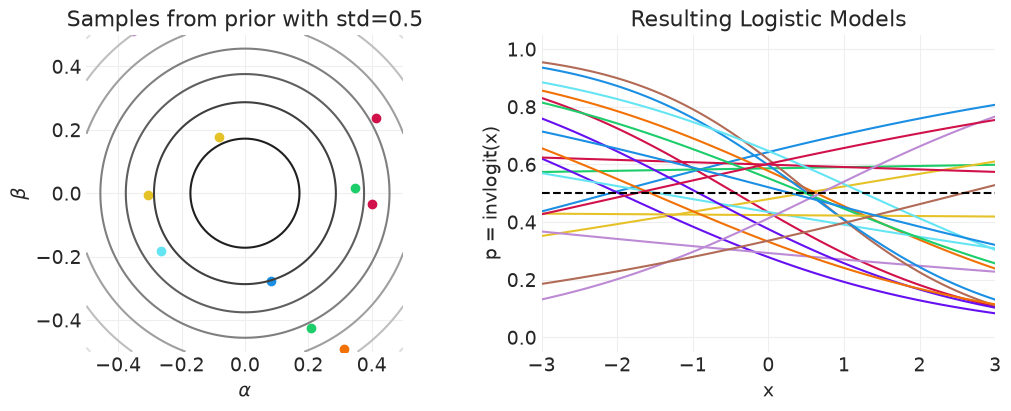

In [14]:
plot_logistic_prior_predictive(prior_std=0.5)

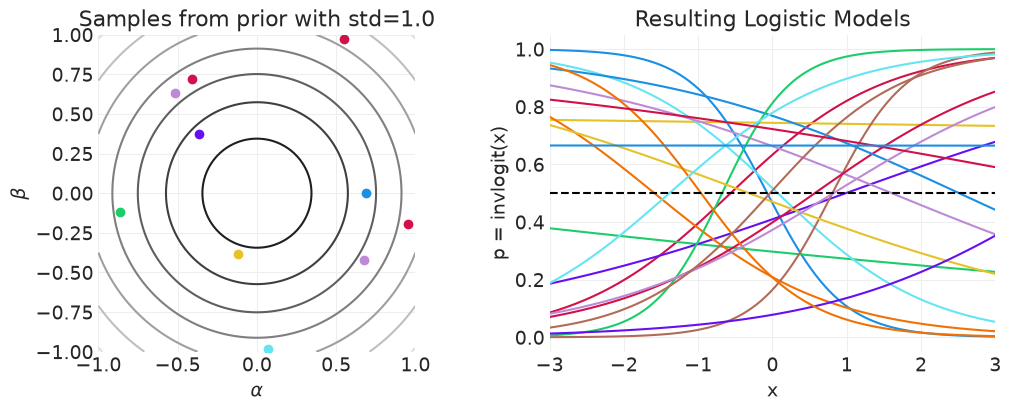

In [15]:
plot_logistic_prior_predictive(prior_std=1.)

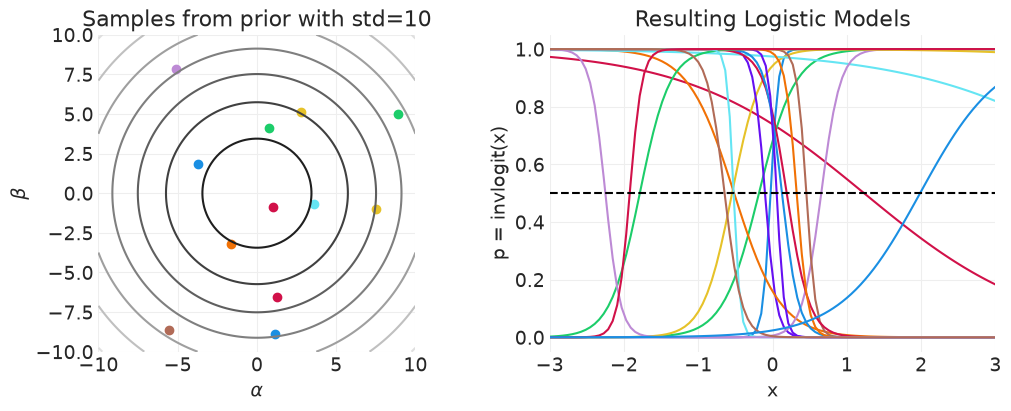

In [16]:
plot_logistic_prior_predictive(prior_std=10)

## Statistical models for admissions
Again, the estimator will depend on the estimand

### Total Causal Effect

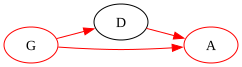

In [17]:
utils.draw_causal_graph(
    edge_list=[
        ("G", "D"),
        ("G", "A"),
        ("D", "A")
    ],
    node_props={
        "G": {"color": "red"},
        "A": {"color": "red"},
    },
    edge_props={
        ("G", "A"): {"color": "red"},
        ("D", "A"): {"color": "red"},
        ("G", "D"): {"color": "red"}
    },
    graph_direction="LR"
)


**Stratify by only Gender**. Don't stratify by Department b.c. it's a Pipe (mediator) that we do not want to block

$$
\begin{align*}
A_i &\sim \text{Bernoulli}(p=p_i) \\
\text{logit}(p_i) &= \alpha[G_i] \\
\alpha &= [\alpha_0, \alpha_1] \\
\alpha_j &\sim \text{Normal}(0, 1)
\end{align*}
$$

### Direct Causal Effect

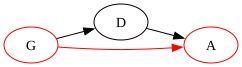

In [18]:
utils.draw_causal_graph(
    edge_list=[
        ("G", "D"),
        ("G", "A"),
        ("D", "A")
    ],
    node_props={
        "G": {"color": "red"},
        "A": {"color": "red"},
    },
    edge_props={
        ("G", "A"): {"color": "red"}
    },
    graph_direction="LR"
)


**Stratify by Gender and Department** to block the Pipe

$$
\begin{align*}
A_i &\sim \text{Bernoulli}(p_i) \\
\text{logit}(p_i) &= \alpha[G_i, D_i] \\
\alpha &= \left[{\begin{array}{cc} \alpha_{0,0}, \alpha_{0,1} \\ \alpha_{1,0}, \alpha_{1,1} \end{array}}\right] \\
\alpha_{j,k} &\sim \text{Normal}(0, 1)
\end{align*}
$$

### Fitting Total Causal Effect Model

In [19]:
def fit_total_effect_model_admissions(data):
    """Fit total effect model, stratifying by gender.
    
    Note
    ----
    We use the Binomial regression, so simulated observation-level
    data from above must be pre-aggregated. (see the function
    `aggregate_admissions_data` below). We could have
    used a Bernoulli likelihood (Logistic regression) for the simulated
    data, but given that we only have aggregates for the real
    UC Berkeley data we choose this more general formulation.
    """

    # Set up observations / coords
    n_admitted = data['admit'].values
    n_applications = data['applications'].values

    gender_coded, gender = pd.factorize(data['applicant.gender'].values)
    
    with pm.Model(coords={"gender": gender}) as total_effect_model:

        # Mutable data for running any gender-based counterfactuals
        gender_coded = pm.Data("gender_id", gender_coded, dims="obs_ids")
        
        alpha = pm.Normal('alpha', 0, 1, dims="gender")
        
        # Record the inverse linked probabilities for reporting
        pm.Deterministic("p_accept", pm.math.invlogit(alpha), dims='gender')
        
        p = pm.math.invlogit(alpha[gender_coded])
        
        likelihood = pm.Binomial("accepted", n=n_applications, p=p, observed=n_admitted, dims="obs_ids")
        total_effect_inference = pm.sample()
    
    return total_effect_model, total_effect_inference

def aggregate_admissions_data(raw_admissions_data):
    """Aggregate simulated data from `simulate_admissions_data`, which
    is in long format to short format, by so that it can be modeled
    using Binomial likelihood. We also recode column names to have the
    same fields as the UC Berkeley dataset so that we can use the
    same model-fitting functions.
    """
    
    # Aggregate applications, admissions, and rejections. Rename
    # columns to have the  same fields as UC Berkeley dataset
    applications = raw_admissions_data.groupby(["gender", "department"]).count().reset_index()
    applications.rename(columns={"accepted": "applications"}, inplace=True)
    
    admits = raw_admissions_data.groupby(["gender", "department"]).sum().reset_index()
    admits.rename(columns={"accepted": "admit"}, inplace=True)
    
    data = applications.merge(admits)
    data.loc[:, "reject"] = data.applications - data.admit
    
    # Code gender & department. For easier comparison to lecture,
    # we use 1-indexed gender/department indicators like McElreath
    data.loc[:, "applicant.gender"] = data.gender.apply(lambda x: 2 if x else 1)
    data.loc[:, "dept"] = data.department.apply(lambda x: 2 if x else 1)
    
    return data[["applicant.gender", "dept", "applications", "admit", "reject"]]

def plot_admissions_model_posterior(inference, figsize=(6, 2)):
    _, ax = plt.subplots(figsize=figsize)

    # Plot alphas
    utils.plot_forest(inference, var_names=['alpha'], hdi_prob=.89, ax=ax);

    # Plot inver-linked acceptance probabilities
    _, ax = plt.subplots(figsize=figsize)
    utils.plot_forest(inference, var_names=['p_accept'], hdi_prob=.89, ax=ax);

    return az.summary(inference)

### Fit Total Effect model on BIASED simulated admissions

In [20]:
SIMULATED_BIASED_ADMISSIONS, _ = simulate_admissions_data("biased")
SIMULATED_BIASED_ADMISSIONS = aggregate_admissions_data(SIMULATED_BIASED_ADMISSIONS)
SIMULATED_BIASED_ADMISSIONS

,applicant.gender,dept,applications,admit,reject
0,1,1,335,13,322
1,1,2,173,34,139
2,2,1,106,11,95
3,2,2,386,108,278


In [21]:
total_effect_model_simulated_biased, total_effect_inference_simulated_biased = fit_total_effect_model_admissions(SIMULATED_BIASED_ADMISSIONS)


NUTS[nutpie]: [alpha]


,mean,sd,hdi89_lb,hdi89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
alpha[1],-2.24,0.149,-2.5,-2,4052,2512,1.00,0.0023,0.0026
alpha[2],-1.132,0.104,-1.3,-0.97,4165,2634,1.00,0.0016,0.0017
p_accept[1],0.097,0.013,0.077,0.12,4052,2512,1.00,0.0002,0.00023
p_accept[2],0.2444,0.0192,0.21,0.27,4165,2634,1.00,0.0003,0.00031


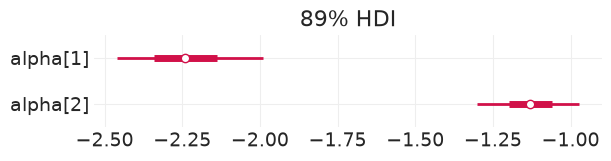

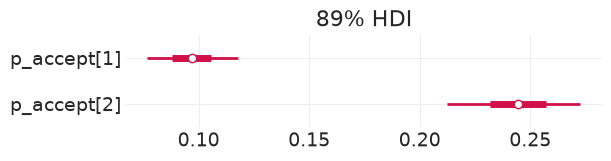

In [22]:
plot_admissions_model_posterior(total_effect_inference_simulated_biased, (6, 1.5))

### Fit Total Effect model on UNBIASED simulated admissions

In [23]:
SIMULATED_UNBIASED_ADMISSIONS, _ = simulate_admissions_data("unbiased")
SIMULATED_UNBIASED_ADMISSIONS = aggregate_admissions_data(SIMULATED_UNBIASED_ADMISSIONS)
SIMULATED_UNBIASED_ADMISSIONS

,applicant.gender,dept,applications,admit,reject
0,1,1,335,33,302
1,1,2,173,60,113
2,2,1,106,8,98
3,2,2,386,111,275


In [24]:
total_effect_model_simulated_unbiased, total_effect_inference_simulated_unbiased = fit_total_effect_model_admissions(SIMULATED_UNBIASED_ADMISSIONS)


NUTS[nutpie]: [alpha]


,mean,sd,hdi89_lb,hdi89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
alpha[1],-1.481,0.115,-1.7,-1.3,4134,2953,1.00,0.0018,0.0017
alpha[2],-1.136,0.105,-1.3,-0.96,4172,3047,1.00,0.0016,0.0016
p_accept[1],0.1859,0.0174,0.16,0.21,4134,2953,1.00,0.00027,0.00026
p_accept[2],0.2436,0.0193,0.21,0.27,4172,3047,1.00,0.0003,0.00029


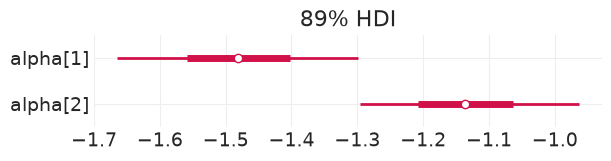

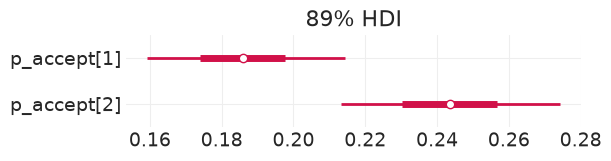

In [25]:
plot_admissions_model_posterior(total_effect_inference_simulated_unbiased, (6, 1.5))

## Fitting Direct Causal Effect Model

In [26]:
def fit_direct_effect_model_admissions(data):
    """Fit total effect model, stratifying by gender.
    
    Note
    ----
    We use the Binomial likelihood, so simulated observation-level data from
    above must be pre-aggregated. (see the function `aggregate_admissions_data`
    below). We could have used a Bernoulli likelihood for the simulated data,
    but given that we only have aggregates for the real UC Berkeley data we
    choose this more general formulation.
    """

    # Set up observations / coords
    n_admitted = data['admit'].values
    n_applications = data['applications'].values
    
    department_coded, department = pd.factorize(data['dept'].values)
    gender_coded, gender = pd.factorize(data['applicant.gender'].values)
    
    with pm.Model(coords={"gender": gender, "department": department}) as direct_effect_model:

        # Mutable data for running any gender-based or department-based counterfactuals
        gender_coded = pm.Data("gender_id", gender_coded, dims="obs_ids")
        department_coded = pm.Data("department_id", department_coded, dims="obs_ids")
        n_applications = pm.Data("n_applications", n_applications, dims="obs_ids")

        alpha = pm.Normal('alpha', 0, 1, dims=["department", "gender"])
        
        # Record inverse linked probabilities for reporting
        pm.Deterministic("p_accept", pm.math.invlogit(alpha), dims=['department', 'gender'])
        
        p = pm.math.invlogit(alpha[department_coded, gender_coded])
        
        likelihood = pm.Binomial("accepted", n=n_applications, p=p, observed=n_admitted, dims="obs_ids")
        direct_effect_inference = pm.sample()
    
    return direct_effect_model, direct_effect_inference

### Fit Direct Effect model to BIASED simulated admissions data

In [27]:
direct_effect_model_simulated_biased, direct_effect_inference_simulated_biased = fit_direct_effect_model_admissions(SIMULATED_BIASED_ADMISSIONS)


NUTS[nutpie]: [alpha]


,mean,sd,hdi89_lb,hdi89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
"alpha[1, 1]",-3.019,0.248,-3.4,-2.6,7122,3601,1.00,0.003,0.0042
"alpha[1, 2]",-2.001,0.293,-2.5,-1.5,6298,3067,1.00,0.0037,0.0045
"alpha[2, 1]",-1.371,0.188,-1.7,-1.1,6088,3345,1.00,0.0024,0.0029
"alpha[2, 2]",-0.938,0.112,-1.1,-0.75,6565,3537,1.00,0.0014,0.0018
"p_accept[1, 1]",0.0478,0.0111,0.03,0.064,7122,3601,1.00,0.00013,0.00018
"p_accept[1, 2]",0.1225,0.0309,0.071,0.17,6298,3067,1.00,0.00039,0.0005
"p_accept[2, 1]",0.2041,0.0302,0.16,0.25,6088,3345,1.00,0.00038,0.00046
"p_accept[2, 2]",0.282,0.0227,0.24,0.32,6565,3537,1.00,0.00028,0.00035


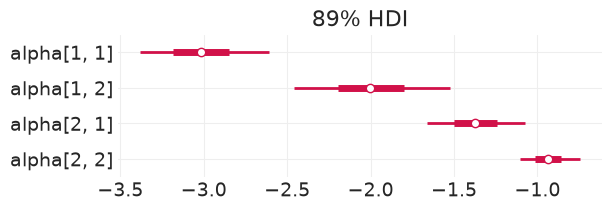

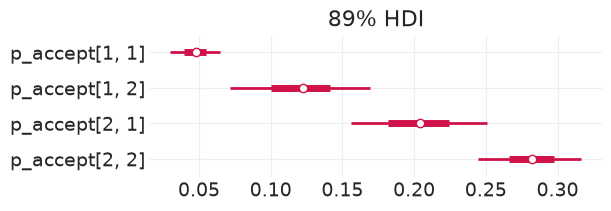

In [28]:
plot_admissions_model_posterior(direct_effect_inference_simulated_biased)

For comparison, here's the ground truth biased admission rates, which we're able to mostly recover:

In [29]:
# Department x Gender
BIASED_ACCEPTANCE_RATES

array([[0.05, 0.1 ],
       [0.2 , 0.3 ]])

### Fit Direct Effect model to UNBIASED simulated admissions data

In [30]:
direct_effect_model_simulated_unbiased, direct_effect_inference_simulated_unbiased = fit_direct_effect_model_admissions(SIMULATED_UNBIASED_ADMISSIONS)


NUTS[nutpie]: [alpha]


,mean,sd,hdi89_lb,hdi89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
"alpha[1, 1]",-2.157,0.173,-2.4,-1.9,7413,3050,1.00,0.002,0.0026
"alpha[1, 2]",-2.271,0.32,-2.8,-1.8,6799,3239,1.00,0.0039,0.0056
"alpha[2, 1]",-0.62,0.157,-0.88,-0.38,6359,3345,1.00,0.002,0.0023
"alpha[2, 2]",-0.899,0.11,-1.1,-0.72,6662,3375,1.00,0.0014,0.0017
"p_accept[1, 1]",0.1048,0.0161,0.077,0.13,7413,3050,1.00,0.00018,0.00024
"p_accept[1, 2]",0.097,0.0273,0.053,0.14,6799,3239,1.00,0.00033,0.00048
"p_accept[2, 1]",0.3507,0.036,0.29,0.41,6359,3345,1.00,0.00045,0.00053
"p_accept[2, 2]",0.2898,0.0226,0.26,0.33,6662,3375,1.00,0.00028,0.00034


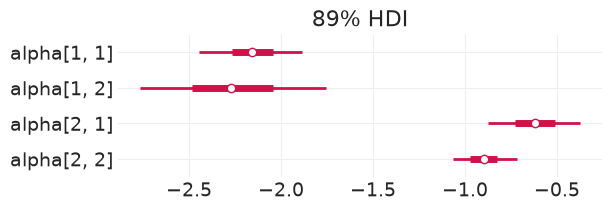

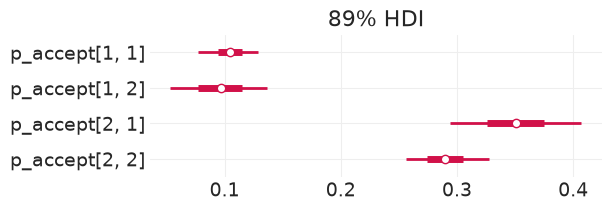

In [31]:
plot_admissions_model_posterior(direct_effect_inference_simulated_unbiased)

For comparison, here's the ground truth unbiased admission rates, which were able to recover:

In [32]:
# Department x Gender
UNBIASED_ACCEPTANCE_RATES

array([[0.1, 0.1],
       [0.3, 0.3]])

# 4. Analyze the UC Berkeley Admissions data

### Review of the counts dataset
- we'll use these counts data to model log odds of acceptance rate for gender/department
- note that we'll be using Binomial Regression, which is equivalent to Bernoulli regression, but operates on aggregate counts, as oppose to individual binary trials
  - The examples above were actually implemented as Binomial Regression so that we can re-use code and demonstrate general patterns of analysis
  - Either way, you'll get the same inference using both approaches

In [33]:
ADMISSIONS

,dept,applicant.gender,admit,reject,applications
1,A,male,512,313,825
2,A,female,89,19,108
3,B,male,353,207,560
4,B,female,17,8,25
5,C,male,120,205,325
6,C,female,202,391,593
7,D,male,138,279,417
8,D,female,131,244,375
9,E,male,53,138,191
10,E,female,94,299,393


### Fit Total Effect model to UC Berkeley admissions data

> Don't forget to look at diagnostics, which we'll skip here

In [34]:
total_effect_model, total_effect_inference = fit_total_effect_model_admissions(ADMISSIONS)

NUTS[nutpie]: [alpha]


,mean,sd,hdi89_lb,hdi89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
alpha[male],-0.22,0.038,-0.28,-0.16,4246,2987,1.00,0.00058,0.00059
alpha[female],-0.829,0.051,-0.91,-0.75,4155,2961,1.00,0.00079,0.00076
p_accept[male],0.4452,0.0094,0.43,0.46,4246,2987,1.00,0.00014,0.00015
p_accept[female],0.304,0.0107,0.29,0.32,4155,2961,1.00,0.00017,0.00016


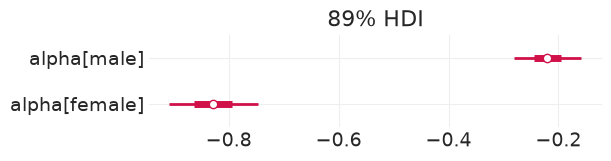

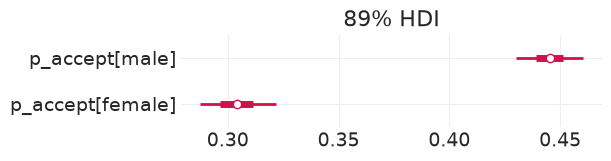

In [35]:
plot_admissions_model_posterior(total_effect_inference, figsize=(6, 1.5))

### Total Causal Effect

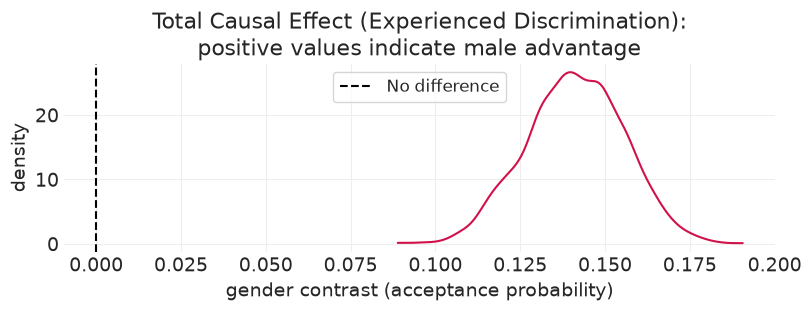

In [36]:
# Total Causal Effect
female_p_accept = total_effect_inference.posterior["p_accept"].sel(gender="female")
male_p_accept = total_effect_inference.posterior["p_accept"].sel(gender="male")
contrast = male_p_accept - female_p_accept

plt.subplots(figsize=(8, 3))
utils.plot_dist(contrast)
plt.axvline(0, linestyle="--", color='black', label='No difference')
plt.xlabel("gender contrast (acceptance probability)")
plt.ylabel("density")
plt.title("Total Causal Effect (Experienced Discrimination):\npositive values indicate male advantage")
plt.legend();

### Fit Direct Effect model to UC Berkeley admissions data

In [37]:
direct_effect_model, direct_effect_inference = fit_direct_effect_model_admissions(ADMISSIONS)

NUTS[nutpie]: [alpha]


,mean,sd,hdi89_lb,hdi89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
"alpha[A, male]",0.49,0.073,0.38,0.61,6701,3370,1.00,0.00089,0.0013
"alpha[A, female]",1.474,0.245,1.1,1.9,5752,2935,1.00,0.0033,0.004
"alpha[B, male]",0.53,0.088,0.39,0.66,6512,3157,1.00,0.0011,0.0014
"alpha[B, female]",0.65,0.4,-0.0025,1.3,6278,3089,1.00,0.005,0.0069
"alpha[C, male]",-0.53,0.11,-0.69,-0.34,5597,3380,1.00,0.0015,0.0018
"alpha[C, female]",-0.658,0.087,-0.79,-0.51,6142,3100,1.00,0.0011,0.0014
"alpha[D, male]",-0.698,0.104,-0.86,-0.54,6491,3353,1.00,0.0013,0.0017
"alpha[D, female]",-0.615,0.106,-0.79,-0.45,6224,2865,1.00,0.0013,0.0017
"alpha[E, male]",-0.936,0.16,-1.2,-0.67,6627,3191,1.00,0.002,0.0026
"alpha[E, female]",-1.143,0.119,-1.3,-0.95,6304,3193,1.00,0.0015,0.002


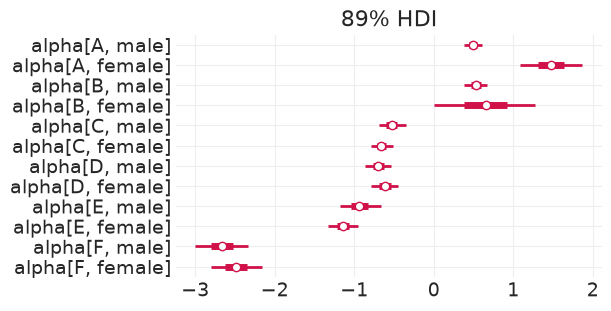

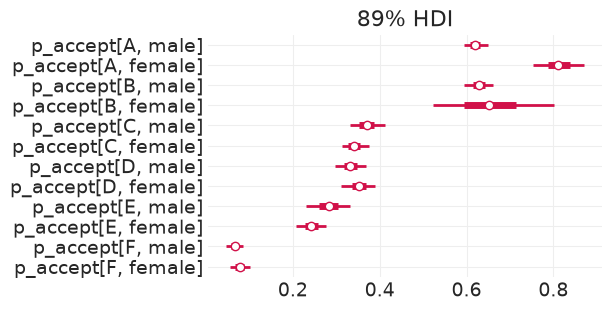

In [38]:
plot_admissions_model_posterior(direct_effect_inference, figsize=(6, 3))

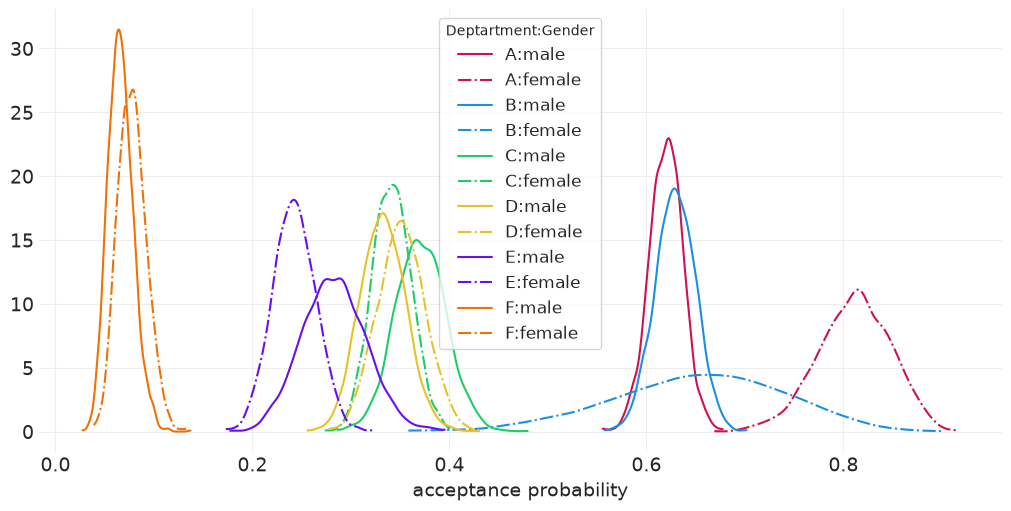

In [39]:
# Fancier plot of department/gender acceptance probability distributions
_, ax = plt.subplots(figsize=(10, 5))
for ii, dept in enumerate(ADMISSIONS.dept.unique()):
    color = f"C{ii}"
    for gend in ADMISSIONS["applicant.gender"].unique():
        label = f"{dept}:{gend}"
        linestyle = "-." if gend == 'female' else "-"
        post = direct_effect_inference.posterior['p_accept'].sel(department=dept, gender=gend)
        utils.plot_dist(post, label=label, color=color, plot_kwargs={"linestyle": linestyle})
plt.xlabel("acceptance probability");
plt.legend(title='Deptartment:Gender');

### Direct Causal Effect

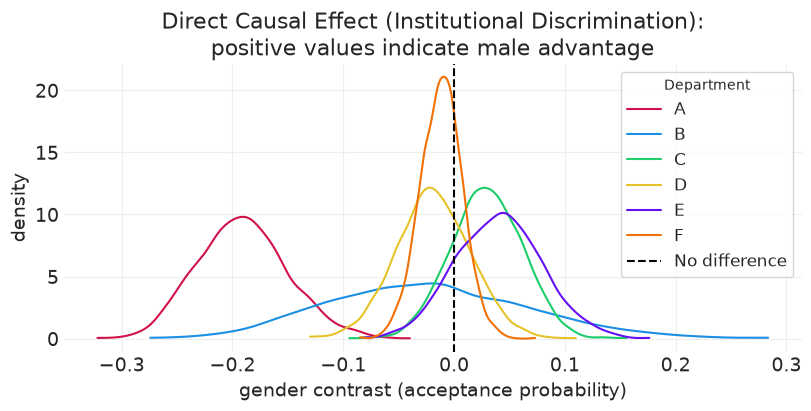

In [40]:
# Direct Causal Effect
_, ax = plt.subplots(figsize=(8, 4))

for ii, dept in enumerate(ADMISSIONS.dept.unique()):
    color = f"C{ii}"
    label = f"{dept}"
    
    female_p_accept = direct_effect_inference.posterior["p_accept"].sel(gender="female", department=dept)
    male_p_accept = direct_effect_inference.posterior["p_accept"].sel(gender="male", department=dept)
    
    contrast = male_p_accept - female_p_accept
    utils.plot_dist(contrast, color=color, label=label)
    
plt.xlabel("gender contrast (acceptance probability)")
plt.ylabel("density")
plt.title("Direct Causal Effect (Institutional Discrimination):\npositive values indicate male advantage")
plt.axvline(0, linestyle="--", color='black', label='No difference');
plt.legend(title='Department');

### Average Direct Effect
- The causal effect of gender **averaged across departments** (marginalize)
- Depends on the distribution of applications to each deparment
- This is easy to do as a simulation

#### Post-stratification
- **Re-weight estimates** for the target population
- allows us to apply model fit from one university to estiamte causal impact at another university with a different distribution of departments
- Here, we use the empirical distribution for re-weighting estimates

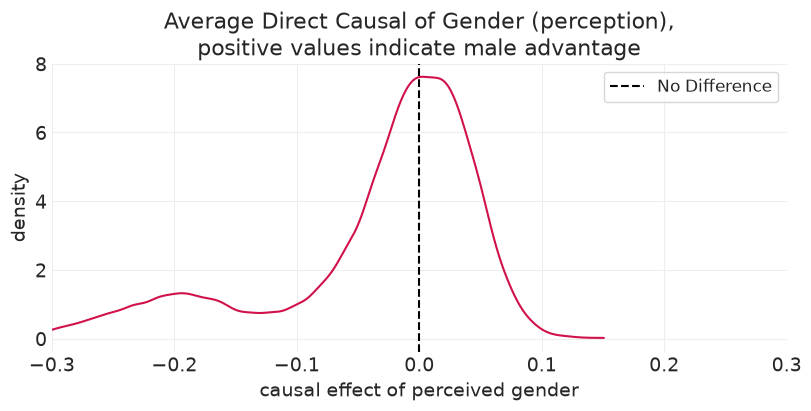

In [41]:
# Use the empirical distribution of departments -- we'd update this for a different university
applications_per_dept = ADMISSIONS.groupby('dept').sum()['applications'].values
total_applications = applications_per_dept.sum()
department_weight = applications_per_dept / total_applications

female_alpha = direct_effect_inference.posterior.sel(gender='female')['alpha']
male_alpha = direct_effect_inference.posterior.sel(gender='male')['alpha']

weighted_female_alpha = female_alpha * department_weight
weighed_male_alpha = male_alpha * department_weight

contrast = weighed_male_alpha - weighted_female_alpha

_, ax = plt.subplots(figsize=(8, 4))
utils.plot_dist(contrast)

plt.axvline(0, linestyle='--', color='k', label='No Difference')
plt.xlabel("causal effect of perceived gender")
plt.ylabel("density")
plt.title("Average Direct Causal of Gender (perception),\npositive values indicate male advantage");
plt.xlim([-.3, .3])
plt.legend();

To verify the averaging process, we can look at the contrast of the `p_accept` samples from the posterior, which provides similar results. However, looking ath the posterior obviously wouldn't work for making predictions for an out-of-sample university however.

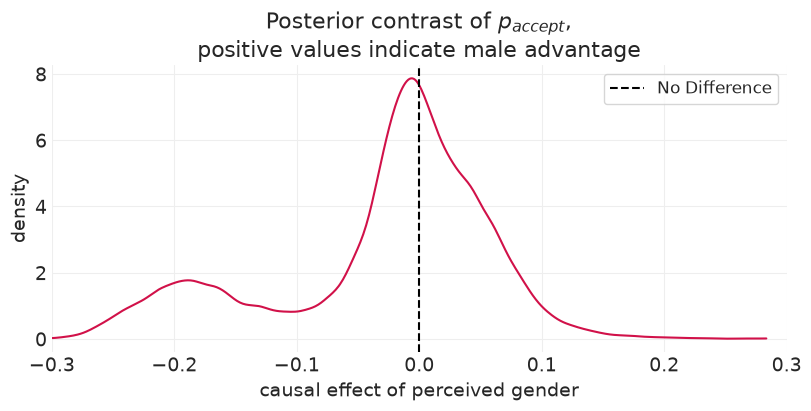

In [42]:
direct_posterior = direct_effect_inference.posterior

# Select by gender; note: p_accept already has link function applied
female_posterior = direct_posterior.sel(gender='female')['p_accept']  # shape: (chain x draw x department)
male_posterior = direct_posterior.sel(gender='male')['p_accept'] # shape: (chain x draw x department)
contrast = male_posterior - female_posterior # shape: (chain x draw x department)

_, ax = plt.subplots(figsize=(8, 4))
# marginalize / collapse the contrast across all departments
utils.plot_dist(contrast);
plt.axvline(0, linestyle='--', color='k', label='No Difference')
plt.xlim([-.3, .3])
plt.xlabel("causal effect of perceived gender")
plt.ylabel("density")
plt.title("Posterior contrast of $p_{accept}$,\npositive values indicate male advantage");
plt.legend();

## Discrimination?
Hard to say
- Big structural effects
- Distribution of applicants could be due to discrimination
- **Confounds are likely**

# BONUS: Survival Analysis
- Counts often modeled as time-to-event (i.e. Exponential or Gamma distribution)  -- Goal is to estimate event rate
- Tricky b.c. ignoring **censored data** can lead to inferential errors
  - **Left censored**: we don't know when the timer started
  - **Right censored** the observation period finished before the event had time to happen

## Example: Austin Cat Adoption

- 20k cats
- Events: adopted (1) or not (0)
- Censoring mechanisms
  - death before adoption
  - escape
  - not adopted yet

**Goal**: determine if Black are adopted at a lower rate than non-Black cats.

In [43]:
CATS = utils.load_data('AustinCats')
CATS.head()

,id,days_to_event,date_out,out_event,date_in,in_event,breed,color,intake_age
0,A730601,1,07/08/2016 09:00:00 AM,Transfer,07/07/2016 12:11:00 PM,Stray,Domestic Shorthair Mix,Blue Tabby,7
1,A679549,25,06/16/2014 01:54:00 PM,Transfer,05/22/2014 03:43:00 PM,Stray,Domestic Shorthair Mix,Black/White,1
2,A683656,4,07/17/2014 04:57:00 PM,Adoption,07/13/2014 01:20:00 PM,Stray,Snowshoe Mix,Lynx Point,2
3,A709749,41,09/22/2015 12:49:00 PM,Transfer,08/12/2015 06:29:00 PM,Stray,Domestic Shorthair Mix,Calico,12
4,A733551,9,09/01/2016 12:00:00 AM,Transfer,08/23/2016 02:35:00 PM,Stray,Domestic Shorthair Mix,Brown Tabby/White,1


### Modeling outcome variable: `days_to_event`
Two go-to distributions for modeling time-to-event

**Exponential Distribution**:
- simpler of the two (single parameter)
- assumes constant rate
- maximum entropy distribution amongst the set of non-negative continuous distributions that have the same average rate.
- assumes a single thing to occur (e.g. part failure) before an event occurs (machine breakdown)

**Gamma Distribution**
- more complex of the two (two parameters)
- maximum entropy distribution amongst the set of distributions with the same mean and average log.
- assumes multiple things to happen (e.g. part failures) before an event occurs (machine breakdown)

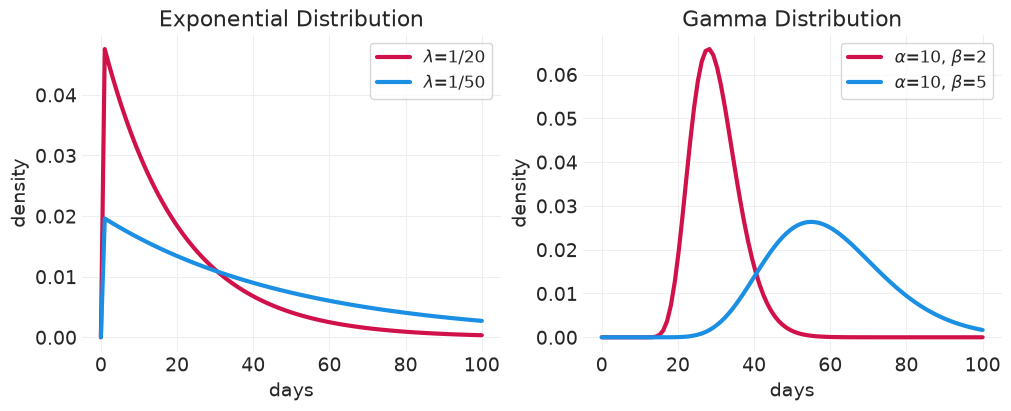

In [44]:
_, axs = plt.subplots(1, 2, figsize=(10, 4))

days = np.linspace(0, 100, 100)

plt.sca(axs[0])
for scale in [20, 50]:
    expon = stats.expon(loc=.01, scale=scale)
    utils.plot_line(days, expon.pdf(days), label=f"$\\lambda$=1/{scale}")
plt.xlabel("days")
plt.ylabel("density")
plt.legend()
plt.title("Exponential Distribution")


plt.sca(axs[1])
N = 8
alpha=10
for scale in [2, 5]:
    gamma = stats.gamma(a=10, loc=alpha, scale=scale)
    utils.plot_line(days, gamma.pdf(days), label=f"$\\alpha$={alpha}, $\\beta$={scale}")
plt.xlabel("days")
plt.ylabel("density")
plt.legend();
plt.title("Gamma Distribution");


## Censored and un-censored observations
- Observed data use the Cumulative distribution; i.e. the **probability that the event occurred by time x**
- Unobserved (censored) data instead require the Complementary of the CDF; i.e. the **probability that the event hasn't happened yet**. 

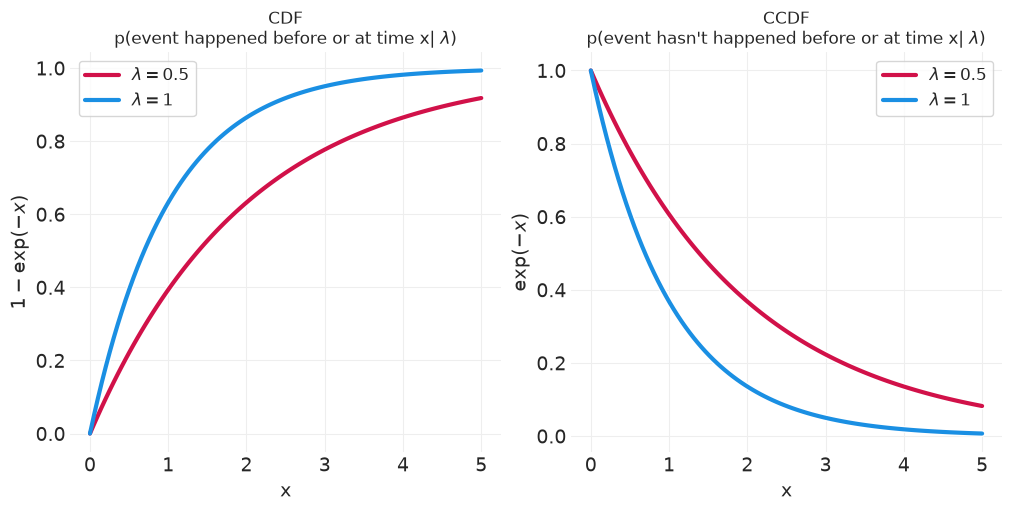

In [45]:
xs = np.linspace(0, 5, 100)
_, axs = plt.subplots(1, 2, figsize=(10, 5))
plt.sca(axs[0])
cdfs = {}
for lambda_ in [0.5, 1]:
    cdfs[lambda_] = ys = 1 - np.exp(-lambda_ * xs)
    utils.plot_line(xs, ys, label=f"$\\lambda={lambda_}$")
    
plt.xlabel("x")
plt.ylabel("$1 - \\exp(-x)$")
plt.legend()
plt.title("CDF\np(event happened before or at time x| $\\lambda$)", fontsize=12)

plt.sca(axs[1])
for lambda_ in [0.5, 1]:
    ys = 1 - cdfs[lambda_]
    utils.plot_line(xs, ys, label=f"$\\lambda={lambda_}$")
    
plt.xlabel("x")
plt.ylabel("$\\exp(-x)$")
plt.legend()
plt.title("CCDF\np(event hasn't happened before or at time x| $\\lambda$)", fontsize=12);

## Statistical Model

$$
\begin{align*}
D_i | A_i &= 1 \sim \text{Exponential}(\lambda_i) \\
D_i | A_i &= 0 \sim \text{ExponentialCCDF}(\lambda_i) \\
\lambda_i &= \frac{1}{\mu_i} \\
\log \mu_i &= \alpha_{\text{cat color}[i]} \\
\alpha_{Black, Other} &\sim \text{Exponential}(\gamma)
\end{align*}
$$

- $D_i | A_i = 1$ - observed adoptions
- $D_i | A_i = 1$ - not-yet-observed adoptions
- $\alpha_{\text{cat color}[i]}$ log average time-to-adoption for each cat color
- $\log \mu_i$ -- link function ensures $\alpha$s are positive
- $\lambda_i = \frac{1}{\mu_i}$ simplifies estimating average **time-to-adoption**

### Finding reasonable hyperparameter for $\alpha$
We'll need to determine a reasonable data for the Exponential prior mean parameter $\gamma$. To do so, we'll look at the empirical distribution of time to adoption:

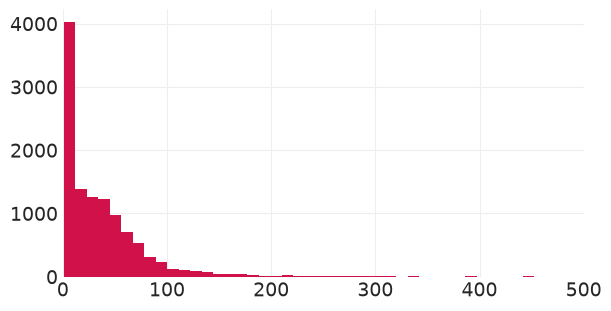

In [46]:
# determine reasonable prior for alpha
plt.subplots(figsize=(6, 3))
CATS[CATS.out_event == 'Adoption'].days_to_event.hist(bins=100)
plt.xlim([0, 500]);

Using the above empirical historgram, we see that a majority of the probablity mass is between zero and 200, so let's use 50 as the expected wait time.

In [47]:
CAT_COLOR_ID, CAT_COLOR = pd.factorize(CATS.color.apply(lambda x: "Other" if x != 'Black' else x))
ADOPTED_ID, ADOPTED = pd.factorize(CATS.out_event.apply(lambda x: "Other" if x != "Adoption" else 'Adopted'))
DAYS_TO_ADOPTION = CATS.days_to_event.values.astype(float)
LAMBDA = 50

with pm.Model(coords={"cat_color": CAT_COLOR}) as adoption_model:
    
    # Censoring
    right_censoring = DAYS_TO_ADOPTION.copy()
    right_censoring[ADOPTED_ID == 0] = DAYS_TO_ADOPTION.max()
    
    # Priors    
    gamma = 1 / LAMBDA
    alpha = pm.Exponential("alpha", gamma, dims="cat_color")
    
    # Likelihood
    log_adoption_rate = 1 / alpha[CAT_COLOR_ID]
    pm.Censored(
        "adopted",
        pm.Exponential.dist(lam=log_adoption_rate),
        lower=None,
        upper=right_censoring,
        observed=DAYS_TO_ADOPTION
    )
    adoption_inference = pm.sample()

NUTS[nutpie]: [alpha]


## Poor black kittes 🐈‍⬛
It appears that black cats DO take longer to get adopted.

#### Posterior Summary

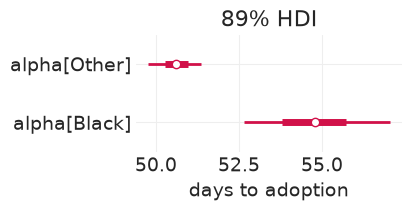

In [48]:
_, ax = plt.subplots(figsize=(4, 2))
utils.plot_forest(adoption_inference, var_names=['alpha'], hdi_prob=.89, ax=ax)
plt.xlabel("days to adoption");

#### Posterior distributions

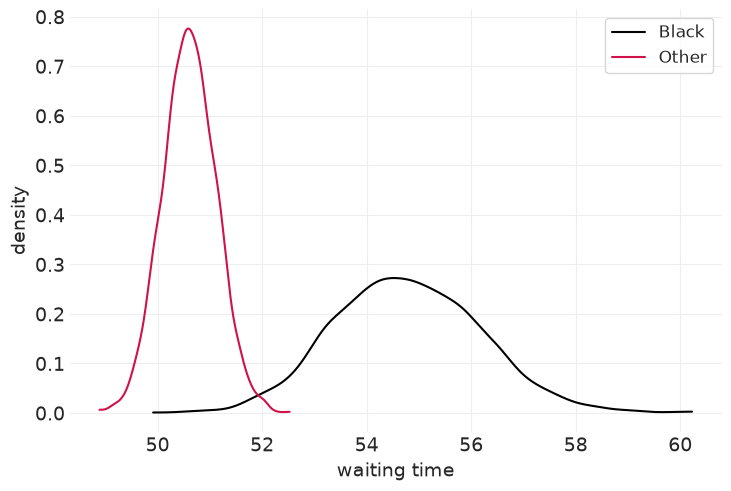

In [49]:
for ii, cat_color in enumerate(["Black", "Other"]):
    color = 'black' if cat_color == 'Black' else "C0"
    posterior_alpha = adoption_inference.posterior.sel(cat_color=cat_color)['alpha']
    utils.plot_dist(posterior_alpha, color=color, label=cat_color)
plt.xlabel("waiting time")
plt.ylabel("density")
plt.legend();

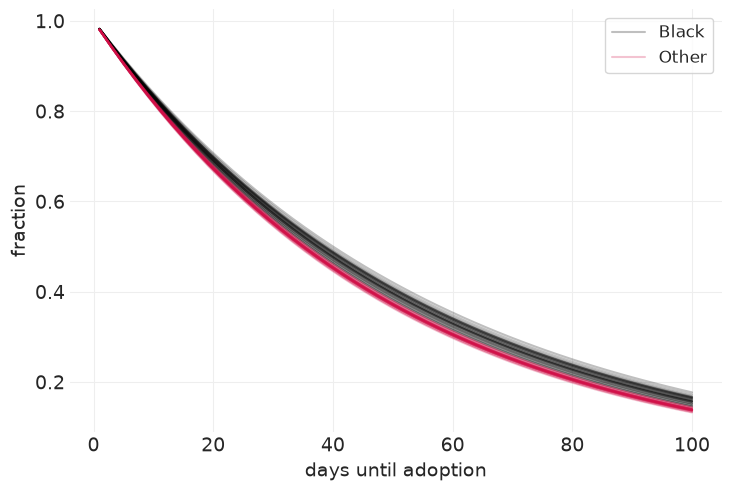

In [50]:
days_until_adoption_ = np.linspace(1, 100)
n_posterior_samples = 25

for cat_color in ['Black', 'Other']:
    color = "black" if cat_color == 'Black' else "C0"
    posterior = adoption_inference.posterior.sel(cat_color=cat_color)
    alpha_samples = posterior.alpha.sel(chain=0)[:n_posterior_samples].values
    for ii, alpha in enumerate(alpha_samples):
        label = cat_color if ii == 0 else None
        plt.plot(days_until_adoption_, np.exp(-days_until_adoption_/alpha), color=color, alpha=.25, label=label)

plt.xlabel("days until adoption")
plt.ylabel("fraction");
plt.legend();